# 12 - Party details and tokens (Dashboard 9)

**Question:** how does the generator write the name-and-address text of the two parties, and what do the token columns say about it?

Columns studied: `ordering_details`, `ordering_tokens`, `beneficiary_details`, `beneficiary_tokens`, with the account, the party type and the bank's country.

- "Sender" = ordering side, "receiver" = beneficiary side. "Bank country" is the country inside the party's own BIC column (characters 5-6), because the details describe the party, not the route.
- The tokens column describes the details text piece by piece, for example `<business:7> <street:13> <post_code:US:5> <country_code:US>`. It is used here as the generator's own description of what each piece is.
- Notebook `08_consistency` already covers the account line (`/account`, `//account` or none) and the 35-character line limit. This notebook does not repeat them.
- Charts are saved to `reports/figures/` with the prefix `PD` (party details).

**Running time.** The text columns are large. The first run builds two working tables (one per side) and stores them in `data/interim/details_tokens.duckdb`; this takes a few minutes. Later runs reuse them and take seconds.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda
from src import settings as S

DB_FILE = S.INTERIM_DIR / "details_tokens.duckdb"       # working database for this notebook only (gitignored)
con = eda.connect(db_file=DB_FILE)
q = eda.q

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

EXPECTED_ROWS = 10_000_000
IBAN = r"_FAKE_[A-Z]{2}\d{20}"
NOISE = "finance_word|stop_word|numerical|other_word"        # token types that are not part of the name or address
BLUE, ORANGE, RED, GREEN, GREY = "#4C72B0", "#DD8452", "#C44E52", "#55A868", "#8C8C8C"
SIDES = {"sender": ("ordering", "sender_country"), "receiver": ("beneficiary", "receiver_country")}

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC


### Working tables `party_sender` and `party_receiver`
One row per payment and side, with the facts extracted from the two text columns once, so that every later query is fast.

In [2]:
def build_party(side):
    """Create party_<side> if it does not exist yet. One pass over the two text columns of that side."""
    prefix, country_col = SIDES[side]
    existing = q("SELECT table_name FROM information_schema.tables")["table_name"].tolist()
    if f"party_{side}" in existing:
        return
    con.execute(f"""
        CREATE TABLE party_{side} AS
        WITH base AS (
            SELECT {prefix}_bic8 AS bank, {country_col} AS bank_country, {prefix}_type AS party_type, {prefix}_account AS account,
                   {prefix}_details AS details, {prefix}_tokens AS tokens,
                   split_part({prefix}_details, chr(10), 1) AS line1, split_part({prefix}_tokens, chr(10), 1) AS token_line1,
                   substr({prefix}_account, 7) AS account_text, anomaly_type
            FROM feat
        )
        SELECT bank, bank_country, party_type, account, anomaly_type IS NOT NULL AS is_anomaly,
               regexp_full_match(account, '{IBAN}')                                   AS is_iban,
               CASE WHEN starts_with(line1, '//') THEN 2 WHEN starts_with(line1, '/') THEN 1 ELSE 0 END AS account_line_slashes,
               regexp_matches(details, '(^|\\n)[0-9]/')                              AS numbered_layout,
               len(string_split(details, chr(10)))                                    AS n_lines,
               regexp_full_match(details, '(/[^\n]*\n)?[0-9]{{4}}[A-Z]{{2}}[A-Z0-9]{{2}}')   AS bic_only,            -- nothing but a BIC after the account line
               ends_with(details, bank)                                               AS ends_with_own_bic,
               regexp_extract(tokens, '<country_(?:code|name):([A-Z]{{2}})', 1)       AS address_country,
               contains(tokens, '<business:')                                         AS has_business,
               contains(tokens, '<company_keyword:')                                  AS has_company_keyword,
               contains(tokens, '<first_name:')                                       AS has_first_name,
               contains(tokens, '<last_name:')                                        AS has_last_name,
               regexp_matches(tokens, '<(finance_word|stop_word):')                   AS has_extra_words,
               hash(trim(regexp_replace(regexp_replace(tokens, '<({NOISE}|line_break|truncation):[^>]*>', '', 'g'), '\\s+', ' ', 'g'))) AS identity_hash,
               CASE WHEN NOT starts_with(line1, '/') THEN 'no account line'
                    WHEN token_line1 IN ('/<iban:22>', '/<separator:/><iban:22>') THEN 'iban token'
                    WHEN token_line1 IN ('/<chr:' || regexp_replace(regexp_replace(account_text, '[0-9]', '9', 'g'), '[A-Z]', 'A', 'g') || '>',
                                         '/<separator:/><chr:' || regexp_replace(regexp_replace(account_text, '[0-9]', '9', 'g'), '[A-Z]', 'A', 'g') || '>')
                         THEN 'character-pattern token'
                    ELSE 'other token' END                                            AS account_token
        FROM base
    """)

for side in SIDES:
    build_party(side)
counts = {side: int(q(f"SELECT count(*) AS n FROM party_{side}").loc[0, "n"]) for side in SIDES}
assert all(n == EXPECTED_ROWS for n in counts.values()), f"Expected {EXPECTED_ROWS:,} rows per side, found {counts}"
N = EXPECTED_ROWS
print({side: f"{n:,} rows" for side, n in counts.items()})

{'sender': '10,000,000 rows', 'receiver': '10,000,000 rows'}


## 1. Hypotheses

H-T1 to H-T5 were written **before testing**. H-T6 to H-T8 were added after the first results (see the note under the table).

| ID | Hypothesis | Test |
|---|---|---|
| H-T1 | The layout of the details (numbered lines `1/ 2/ 3/` or free text) depends on the country and the party type | Share of numbered layouts by party type and country |
| H-T2 | IBAN-shaped accounts appear only for certain countries | Share of IBAN-shaped accounts per bank country |
| H-T3 | Names reveal the party type: businesses carry company words, consumers carry first and last names | Name tokens by party type |
| H-T4 | The address is in the country of the party's bank | Country in the address tokens against the bank's country |
| H-T5 | The tokens mirror the details exactly, starting with the account | Account token against the account's own character pattern |
| H-T6 | *(added)* The layout is a fixed property of each account, not a choice made per payment | Share of numbered layouts per account |
| H-T7 | *(added)* An account's name and address never change; what varies between payments is extra words added at the end | Distinct identities per account once the extra-word tokens are removed |
| H-T8 | *(added)* Senders and receivers are written by different rules | Every test above, run separately for the two sides |

**How the hypotheses changed.** H-T1 showed large differences between countries (from none to a sixth of payments) but none between party types, and single banks ranged from 0% to 100%, so the unit had to be smaller than the country: the account (H-T6). The same account appeared with dozens of different detail texts, which looked like a contradiction until the differences turned out to sit only in trailing extra words (H-T7). H-T4 held perfectly for senders and not at all for receivers, and H-T6 and H-T7 then turned out to hold for senders only, which led to H-T8.

## 2. Account format is decided by the bank's country (H-T2)

,side,kind,countries,payments,pct_of_payments
0,receiver,always IBAN-shaped,76,5405035,54.050
1,receiver,never IBAN-shaped,153,4594965,45.950
2,sender,always IBAN-shaped,76,5442631,54.430
3,sender,never IBAN-shaped,152,4557369,45.570


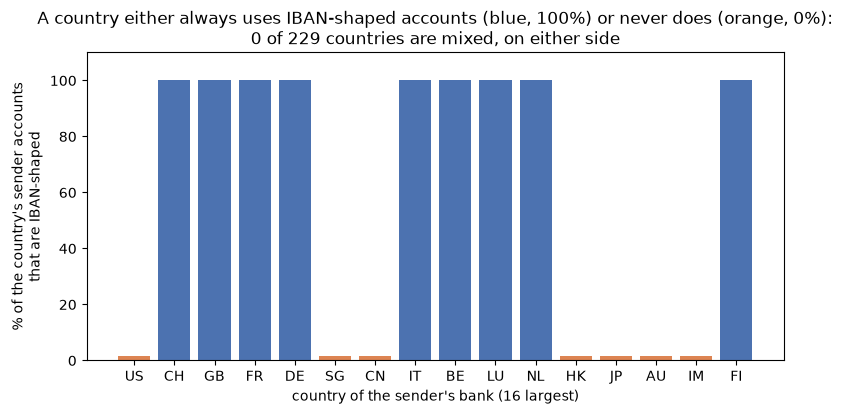

In [3]:
def iban_by_country(side):
    return q(f"""
        SELECT '{side}' AS side, bank_country, count(*) AS payments, count(DISTINCT bank) AS banks, 100 * avg(is_iban::INT) AS pct_iban_shaped
        FROM party_{side} GROUP BY 2
    """)

iban = pd.concat([iban_by_country(s) for s in SIDES], ignore_index=True)
iban["kind"] = np.select([iban.pct_iban_shaped == 0, iban.pct_iban_shaped == 100], ["never IBAN-shaped", "always IBAN-shaped"], default="mixed")
summary = iban.groupby(["side", "kind"]).agg(countries=("bank_country", "size"), payments=("payments", "sum")).reset_index()
summary["pct_of_payments"] = 100 * summary.payments / N
display(summary.round(2))
top = iban[iban.side == "sender"].sort_values("payments", ascending=False).head(16)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(top.bank_country, top.pct_iban_shaped.clip(lower=1.5), color=[BLUE if v == 100 else ORANGE for v in top.pct_iban_shaped])
ax.set_ylim(0, 110)
ax.set_ylabel("% of the country's sender accounts\nthat are IBAN-shaped")
ax.set_xlabel("country of the sender's bank (16 largest)")
mixed = int((iban.kind == "mixed").sum())
ax.set_title(f"A country either always uses IBAN-shaped accounts (blue, 100%) or never does (orange, 0%):\n"
             f"{mixed} of {iban.bank_country.nunique()} countries are mixed, on either side")
eda.save(fig, "PD1_iban_by_country")
plt.show()

**Result: H-T2 held as a strict rule.** Every country falls in one of two groups, on both sides. Together with rule R-S8 (notebook 08) the account can be written down in full for an IBAN country: country, 2 random digits, the bank's 4-digit code, 8 zeros and a 6-digit number.

## 3. The account token mirrors the account (H-T5)

For rows that have an account line, the first token should describe it: `<iban:22>` for an IBAN-shaped account, otherwise `<chr:...>` with the account's own pattern, where every digit is written `9` and every capital letter `A` (account `00E69 0N 873` gives `<chr:99A99 9A 999>`). A leading `<separator:/>` marks the `//` form.

In [4]:
tok = pd.concat([q(f"""
    SELECT '{side}' AS side, CASE WHEN is_iban THEN 'IBAN-shaped' ELSE 'other format' END AS account_format, account_token, count(*) AS payments
    FROM party_{side} WHERE account_line_slashes > 0 GROUP BY 2, 3
""") for side in SIDES], ignore_index=True)
tok["pct_of_format"] = 100 * tok.payments / tok.groupby(["side", "account_format"]).payments.transform("sum")
tok.sort_values(["side", "account_format", "payments"], ascending=[True, True, False]).round(2)

,side,account_format,account_token,payments,pct_of_format
4,receiver,IBAN-shaped,iban token,4977076,98.080
5,receiver,IBAN-shaped,other token,97688,1.920
7,receiver,other format,character-pattern token,4237527,98.190
6,receiver,other format,other token,78327,1.810
2,sender,IBAN-shaped,iban token,5048042,98.280
0,sender,IBAN-shaped,other token,88138,1.720
3,sender,other format,character-pattern token,4201423,97.690
1,sender,other format,other token,99287,2.310


In [5]:
q("""
    SELECT split_part(ordering_details, chr(10), 1) AS account_line, split_part(ordering_tokens, chr(10), 1) AS first_token_line
    FROM feat WHERE starts_with(ordering_details, '/') AND NOT starts_with(ordering_tokens, '/') LIMIT 5
""")

,account_line,first_token_line
0,/PL70004600000000817101,<other_words:24>1/<business:11> <company_keyword:4>
1,/CH52010400000000092105,<other_words:24>1/<first_name:6> <last_name:9>
2,/63I91/46,<other_words:10><other_words:9>
3,/0000000000086045,<other_words:17>
4,/9680 6X2,<other_words:10>1/<last_name:6>


**Result: H-T5 held for the large majority.** The expected token is there in about 98% of rows with an account line. In the rest, the tokeniser did not recognise the account and labelled the whole line as free words (`<other_words:N>`, examples above), so the tokens are a close but not perfect description of the details.

## 4. The name tokens give away the party type (H-T3)

In [6]:
names = pd.concat([q(f"""
    SELECT '{side}' AS side, party_type, count(*) AS payments,
           100 * avg(has_business::INT) AS pct_business_token, 100 * avg(has_company_keyword::INT) AS pct_company_keyword_token,
           100 * avg(has_first_name::INT) AS pct_first_name_token, 100 * avg(has_last_name::INT) AS pct_last_name_token,
           sum(((party_type = 'B' AND (has_first_name OR has_last_name)) OR (party_type = 'C' AND (has_business OR has_company_keyword)))::INT) AS rows_with_the_wrong_kind_of_name,
           100 * avg((has_business OR has_company_keyword OR has_first_name OR has_last_name)::INT) AS pct_with_any_name_token
    FROM party_{side} GROUP BY 2 ORDER BY 2
""") for side in SIDES], ignore_index=True)
names.round(2)

,side,party_type,payments,pct_business_token,pct_company_keyword_token,pct_first_name_token,pct_last_name_token,rows_with_the_wrong_kind_of_name,pct_with_any_name_token
0,sender,B,7874637,85.380,26.310,0.000,0.000,0.000,87.590
1,sender,C,2125363,0.000,0.000,57.130,86.100,0.000,90.660
2,receiver,B,2881550,85.830,26.550,0.000,0.000,0.000,87.740
3,receiver,C,7118450,0.000,0.000,57.950,86.390,0.000,90.850


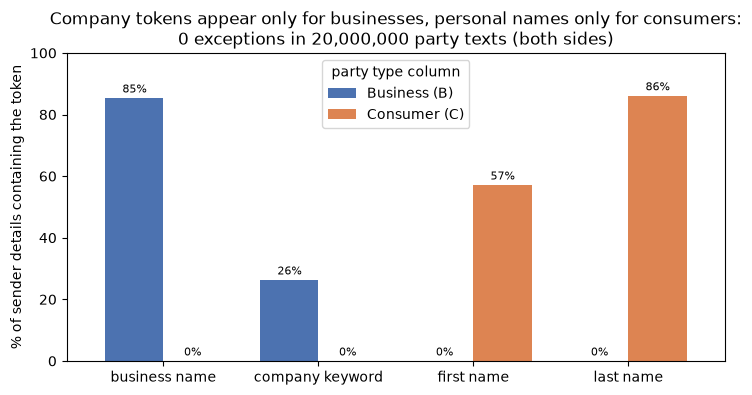

In [7]:
d = names[names.side == "sender"].set_index("party_type")[["pct_business_token", "pct_company_keyword_token", "pct_first_name_token", "pct_last_name_token"]]
d.columns = ["business name", "company keyword", "first name", "last name"]
d.index = ["Business (B)", "Consumer (C)"]
fig, ax = plt.subplots(figsize=(8.5, 4))
d.T.plot.bar(ax=ax, color=[BLUE, ORANGE], rot=0, width=0.75)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f%%", padding=2, fontsize=8)
ax.set_ylim(0, 100)
ax.set_ylabel("% of sender details containing the token")
ax.legend(title="party type column")
wrong = int(names.rows_with_the_wrong_kind_of_name.sum())
ax.set_title(f"Company tokens appear only for businesses, personal names only for consumers:\n"
             f"{wrong:,} exceptions in {2 * N:,} party texts (both sides)")
eda.save(fig, "PD2_name_tokens_by_party_type")
plt.show()

**Result: H-T3 held.** The two kinds of name token never cross over. Wherever a name token is present (last column of the table), the party type can be read from the text alone; the remaining rows have their name tokenised as free words.

## 5. Layout: per country, per party type, or per account? (H-T1, H-T6)

Two layout choices: numbered lines (`1/` name, `2/` street, `3/` country and town) or free text; and the form of the account line (`/`, `//` or none).

In [8]:
lay = pd.concat([q(f"""
    SELECT '{side}' AS side, 'party type' AS dimension, party_type AS segment, count(*) AS payments,
           100 * avg(numbered_layout::INT) AS pct_numbered, 100 * avg((account_line_slashes = 2)::INT) AS pct_double_slash,
           100 * avg((account_line_slashes = 0)::INT) AS pct_no_account_line
    FROM party_{side} GROUP BY 3
    UNION ALL
    SELECT '{side}', 'bank country (8 largest)', bank_country, count(*), 100 * avg(numbered_layout::INT),
           100 * avg((account_line_slashes = 2)::INT), 100 * avg((account_line_slashes = 0)::INT)
    FROM party_{side} WHERE bank_country IN (SELECT bank_country FROM party_{side} GROUP BY 1 ORDER BY count(*) DESC LIMIT 8) GROUP BY 3
""") for side in SIDES], ignore_index=True)
lay.sort_values(["side", "dimension", "payments"], ascending=[False, False, False]).round(2)

,side,dimension,segment,payments,pct_numbered,pct_double_slash,pct_no_account_line
0,sender,party type,B,7874637,15.930,9.140,5.420
1,sender,party type,C,2125363,16.540,8.880,6.400
7,sender,bank country (8 largest),US,1582415,14.800,9.790,6.210
4,sender,bank country (8 largest),CH,786246,16.610,8.120,4.870
6,sender,bank country (8 largest),GB,662529,14.930,9.730,6.600
5,sender,bank country (8 largest),FR,538746,14.380,5.960,5.910
8,sender,bank country (8 largest),DE,509341,14.130,7.930,6.210
9,sender,bank country (8 largest),SG,393191,5.990,20.030,5.610
3,sender,bank country (8 largest),CN,342194,15.240,9.090,5.830
2,sender,bank country (8 largest),IT,298586,14.510,8.660,6.810


Party type makes almost no difference; countries differ a lot. But is the country the cause? For every account with at least 200 payments: in what share of its payments is each layout used?

In [9]:
def per_account(side):
    return q(f"""
        WITH a AS (
            SELECT account, bank, count(*) AS n, avg(numbered_layout::INT) AS share_numbered,
                   count(DISTINCT account_line_slashes) AS account_line_forms, count(DISTINCT identity_hash) AS identities
            FROM party_{side} GROUP BY 1, 2 HAVING count(*) >= 200
        )
        SELECT '{side}' AS side, count(*) AS accounts_with_200_plus_payments, sum(n) AS payments,
               sum((share_numbered = 0)::INT) AS never_numbered, sum((share_numbered = 1)::INT) AS always_numbered,
               sum((share_numbered > 0 AND share_numbered < 1)::INT) AS sometimes_numbered,
               sum((account_line_forms = 1)::INT) AS one_account_line_form, sum((account_line_forms > 1)::INT) AS several_account_line_forms
        FROM a
    """)

acc = pd.concat([per_account(s) for s in SIDES], ignore_index=True).fillna(0)
acc["pct_of_accounts_always_numbered"] = 100 * acc.always_numbered / acc.accounts_with_200_plus_payments.replace(0, np.nan)
acc.round(2)

,side,accounts_with_200_plus_payments,payments,never_numbered,always_numbered,sometimes_numbered,one_account_line_form,several_account_line_forms,pct_of_accounts_always_numbered
0,sender,8532,"5,883,912.000","7,308.000","1,224.000",0.000,"8,532.000",0.000,14.350
1,receiver,5474,"3,540,571.000",0.000,0.000,"5,474.000",0.000,"5,474.000",0.000


,sender_banks_with_5000_plus_payments,lowest_pct_numbered,p10,median_pct,p90,highest_pct_numbered
0,452,0.000,0.000,12.900,29.900,100.000


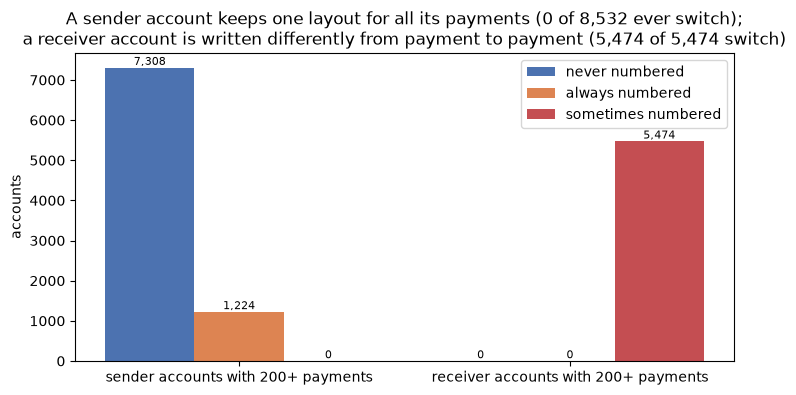

In [10]:
bank_mix = q("""
    WITH b AS (SELECT bank, count(*) AS n, 100 * avg(numbered_layout::INT) AS pct_numbered, count(DISTINCT account) AS accounts
               FROM party_sender GROUP BY 1 HAVING count(*) >= 5000)
    SELECT count(*) AS sender_banks_with_5000_plus_payments, min(pct_numbered) AS lowest_pct_numbered, quantile_cont(pct_numbered, 0.1) AS p10,
           median(pct_numbered) AS median_pct, quantile_cont(pct_numbered, 0.9) AS p90, max(pct_numbered) AS highest_pct_numbered
    FROM b
""")
display(bank_mix.round(1))
a = acc.set_index("side")
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(a))
ax.bar(x - 0.27, a.never_numbered, width=0.27, color=BLUE, label="never numbered")
ax.bar(x, a.always_numbered, width=0.27, color=ORANGE, label="always numbered")
ax.bar(x + 0.27, a.sometimes_numbered, width=0.27, color=RED, label="sometimes numbered")
for i, side in enumerate(a.index):
    for off, col in [(-0.27, "never_numbered"), (0, "always_numbered"), (0.27, "sometimes_numbered")]:
        ax.text(i + off, a.loc[side, col], f"{int(a.loc[side, col]):,}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"{s} accounts with 200+ payments" for s in a.index])
ax.set_ylabel("accounts")
ax.legend()
ax.set_title(f"A sender account keeps one layout for all its payments ({int(a.loc['sender', 'sometimes_numbered']):,} of "
             f"{int(a.loc['sender', 'accounts_with_200_plus_payments']):,} ever switch);\n"
             f"a receiver account is written differently from payment to payment "
             f"({int(a.loc['receiver', 'sometimes_numbered']):,} of {int(a.loc['receiver', 'accounts_with_200_plus_payments']):,} switch)")
eda.save(fig, "PD3_layout_per_account")
plt.show()

The receiver side also has a third form, in which the details hold nothing but a bank code after the account line:

In [11]:
pd.concat([q(f"""
    SELECT '{side}' AS side, party_type, count(*) AS payments, sum(bic_only::INT) AS details_are_only_a_bic,
           100 * avg(bic_only::INT) AS pct_only_a_bic, sum((bic_only AND ends_with_own_bic)::INT) AS of_which_the_partys_own_bank
    FROM party_{side} GROUP BY 2 ORDER BY 2
""") for side in SIDES], ignore_index=True).round(3)

,side,party_type,payments,details_are_only_a_bic,pct_only_a_bic,of_which_the_partys_own_bank
0,sender,B,7874637,"393,435.000",4.996,"393,435.000"
1,sender,C,2125363,"102,411.000",4.819,"102,411.000"
2,receiver,B,2881550,"143,950.000",4.996,"143,950.000"
3,receiver,C,7118450,"355,939.000",5.000,"355,939.000"


**Result: H-T1 was rejected as a cause; H-T6 held for senders only.**

- **Senders:** each account has one layout and one form of account line for all its payments. The differences between countries and banks are differences in which accounts they contain: a bank whose traffic comes from a few large accounts can be anywhere between 0% and 100% (table above).
- **Receivers:** the layout is chosen again for every payment. That is why the receiver rows of the first table show the same share of numbered layouts in every country and for both party types, and why every busy receiver account uses both layouts.

## 6. Where is the party's address? (H-T4, H-T8)

The address tokens name a country (`<country_code:US>`, `<country_name:DE:en-gb>`). Is it the country of the party's bank? Chance = the share expected if the two countries were unrelated.

In [12]:
def address(side):
    d = q(f"""
        SELECT '{side}' AS side, count(*) AS payments, 100 * avg((address_country <> '')::INT) AS pct_with_a_country_token,
               sum((address_country <> '')::INT) AS rows_with_country,
               sum((address_country <> '' AND address_country = bank_country)::INT) AS address_in_bank_country
        FROM party_{side}
    """)
    chance = q(f"""
        WITH a AS (SELECT address_country AS c, count(*) * 1.0 / sum(count(*)) OVER () AS p FROM party_{side} WHERE address_country <> '' GROUP BY 1),
             b AS (SELECT bank_country AS c, count(*) * 1.0 / sum(count(*)) OVER () AS p FROM party_{side} WHERE address_country <> '' GROUP BY 1)
        SELECT 100 * sum(a.p * b.p) AS chance FROM a JOIN b USING (c)
    """).loc[0, "chance"]
    stable = q(f"""
        WITH x AS (SELECT account, bank, count(DISTINCT address_country) FILTER (WHERE address_country <> '') AS k
                   FROM party_{side} GROUP BY 1, 2 HAVING count(*) >= 20)
        SELECT count(*) AS accounts_with_20_plus_payments, sum((k > 1)::INT) AS accounts_with_several_address_countries FROM x
    """)
    d["pct_address_in_bank_country"] = 100 * d.address_in_bank_country / d.rows_with_country
    d["pct_by_chance"] = float(chance)
    d["distinct_address_countries"] = int(q(f"SELECT count(DISTINCT address_country) AS n FROM party_{side} WHERE address_country <> ''").loc[0, "n"])
    return pd.concat([d, stable], axis=1)

addr = pd.concat([address(s) for s in SIDES], ignore_index=True)
addr.round(3)

,side,payments,pct_with_a_country_token,rows_with_country,address_in_bank_country,pct_address_in_bank_country,pct_by_chance,distinct_address_countries,accounts_with_20_plus_payments,accounts_with_several_address_countries
0,sender,10000000,84.537,"8,453,693.000","8,453,693.000",100.000,4.968,226,56400,0.000
1,receiver,10000000,84.875,"8,487,531.000","83,468.000",0.983,1.750,228,47289,0.000


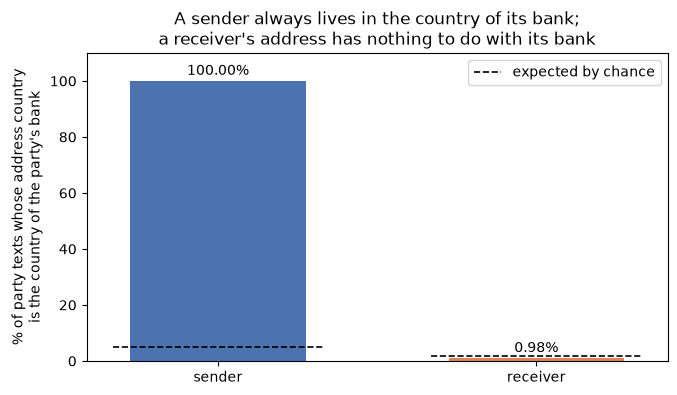

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(addr.side, addr.pct_address_in_bank_country, color=[BLUE, ORANGE], width=0.55)
ax.bar_label(bars, fmt="%.2f%%", padding=2)
for i, c in enumerate(addr.pct_by_chance):
    ax.plot([i - 0.33, i + 0.33], [c, c], color="black", ls="--", lw=1.2, label="expected by chance" if i == 0 else None)
ax.set_ylim(0, 110)
ax.set_ylabel("% of party texts whose address country\nis the country of the party's bank")
ax.legend(loc="upper right")
ax.set_title("A sender always lives in the country of its bank;\na receiver's address has nothing to do with its bank")
eda.save(fig, "PD4_address_vs_bank_country")
plt.show()

**Result: H-T4 held for senders and was rejected for receivers, so H-T8 held.** For both sides the address country never changes for a given account. But the sender's address is always in its bank's country, while the receiver's address matches its bank's country even less often than two unrelated countries would. The two sides are written by different rules.

## 7. A fixed identity, plus extra words now and then (H-T7)

The same account shows up with many different detail texts. To see whether its *identity* changes, the tokens that are not part of a name or address (finance words, stop words, stray numbers and words, line-break markers) are removed, and the distinct remaining token sequences are counted per account.

In [14]:
ident = pd.concat([q(f"""
    WITH a AS (SELECT account, bank, count(*) AS n, count(DISTINCT identity_hash) AS identities FROM party_{side} GROUP BY 1, 2 HAVING count(*) >= 200)
    SELECT '{side}' AS side, count(*) AS accounts_with_200_plus_payments, sum((identities = 1)::INT) AS one_identity,
           sum((identities = 2)::INT) AS two_identities, sum((identities > 2)::INT) AS more_than_two, max(identities) AS most_identities
    FROM a
""") for side in SIDES], ignore_index=True)
ident = ident.fillna(0)
ident["pct_one_identity"] = 100 * ident.one_identity / ident.accounts_with_200_plus_payments.replace(0, np.nan)
display(ident.round(2))
extra = pd.concat([q(f"""
    SELECT '{side}' AS side, 'all payments' AS segment, count(*) AS payments, 100 * avg(has_extra_words::INT) AS pct_with_finance_or_stop_words FROM party_{side}
    UNION ALL SELECT '{side}', 'party type ' || party_type, count(*), 100 * avg(has_extra_words::INT) FROM party_{side} GROUP BY 2
    UNION ALL SELECT '{side}', CASE WHEN is_anomaly THEN 'anomaly rows' ELSE 'normal rows' END, count(*), 100 * avg(has_extra_words::INT) FROM party_{side} GROUP BY 2
    UNION ALL SELECT '{side}', CASE WHEN numbered_layout THEN 'numbered layout' ELSE 'free-text layout' END, count(*), 100 * avg(has_extra_words::INT) FROM party_{side} GROUP BY 2
""") for side in SIDES], ignore_index=True)
extra.sort_values(["side", "segment"], ascending=[False, True]).round(2)

,side,accounts_with_200_plus_payments,one_identity,two_identities,more_than_two,most_identities,pct_one_identity
0,sender,8532,"7,671.000",85.000,776.000,357,89.910
1,receiver,5474,0.000,0.000,"5,474.000",1795,0.000


,side,segment,payments,pct_with_finance_or_stop_words
0,sender,all payments,10000000,11.470
4,sender,anomaly rows,7006,11.280
5,sender,free-text layout,8393681,13.660
3,sender,normal rows,9992994,11.470
6,sender,numbered layout,1606319,0.060
2,sender,party type B,7874637,11.490
1,sender,party type C,2125363,11.410
7,receiver,all payments,10000000,11.610
11,receiver,anomaly rows,7006,11.180
13,receiver,free-text layout,8495529,13.660


In [15]:
# What the extra words look like: the six most common token texts of one busy sender account
q("""
    WITH pick AS (SELECT ordering_account AS account FROM feat GROUP BY 1 HAVING count(*) BETWEEN 300 AND 400 ORDER BY 1 LIMIT 1)
    SELECT replace(ordering_tokens, chr(10), ' | ') AS tokens, count(*) AS payments
    FROM feat WHERE ordering_account = (SELECT account FROM pick) GROUP BY 1 ORDER BY 2 DESC LIMIT 6
""")

,tokens,payments
0,/<chr: .99999999> | <line_break:35><business:17> <other_words:15> <post_code:US:5> <other_words:2> <countr...,255
1,/<chr: .99999999> | <line_break:35><business:17> <other_words:15> <post_code:US:5> <other_words:2> <countr...,4
2,/<chr: .99999999> | <line_break:35><business:17> <other_words:15> <post_code:US:5> <other_words:2> <countr...,3
3,/<chr: .99999999> | <line_break:35><business:17> <other_words:15> <post_code:US:5> <other_words:2> <countr...,2
4,/<chr: .99999999> | <line_break:35><business:17> <other_words:15> <post_code:US:5> <other_words:2> <countr...,2
5,/<chr: .99999999> | <line_break:35><business:17> <other_words:15> <post_code:US:5> <other_words:2> <countr...,2


The same check for a receiver looks very different. The most common texts of one receiver account (line breaks shown as `|`):

In [16]:
q("""
    WITH pick AS (SELECT beneficiary_account AS account, beneficiary_bic8 AS bank FROM feat GROUP BY 1, 2 HAVING count(*) BETWEEN 300 AND 320 ORDER BY 1, 2 LIMIT 1)
    SELECT replace(beneficiary_details, chr(10), ' | ') AS receiver_details, count(*) AS payments, count(DISTINCT ordering_account) AS different_senders
    FROM feat WHERE (beneficiary_account, beneficiary_bic8) IN (SELECT account, bank FROM pick) GROUP BY 1 ORDER BY 2 DESC LIMIT 10
""")

,receiver_details,payments,different_senders
0,/ 00857096 | SHI KE KE JI YOU XIAN GONG SI VZUO | HAN LU 820572 LA SA SHI CN,12,12
1,/ 00857096 | SHI HAN LU VZUO 820572 LA SA SHI | CN,8,8
2,/ 00857096 | SHI VZUO HAN LU 820572 LA SA SHI | CN,8,8
3,/ 00857096 | 0009SGS0,7,6
4,/ 00857096 | 1/SHI KE KE JI YOU XIAN GONG SI | 3/CN/LA SA SHI,7,7
5,/ 00857096 | 1/SHI KE KE JI YOU XIAN GONG SI | 2/VZUO HAN LU 820572 | 3/CN/LA SA SHI,7,7
6,/ 00857096 | 1/SHI SI | 3/CN/LA SA SHI,7,7
7,/ 00857096 | SHI KE KE JI YOU XIAN GONG SI VZUO | HAN LU LA SA SHI CN,7,7
8,/ 00857096 | SHI KE KE JI YOU XIAN GONG SI VZUO | HAN LU 820572 LA SA SHI CHINA,6,6
9,/ 00857096 | SHI SI VZUO HAN LU 820572 LA SA S | HI CHINA,6,6


**Result: H-T7 held for senders only.** A sender's name and address are fixed; what changes between its payments is an occasional line of extra words, added to free-text layouts at the same rate on both sides and almost never to numbered ones (second table). A receiver is one party too (its address country never changes, section 6), but its text is rewritten for each payment: full or shortened name, with or without street and postcode, country as a code or a name, numbered or free, or only the bank code.

## 8. Results: reconstructed rules (all checked on 10,000,000 rows, both sides)

Every number below is printed by a cell above.

### The recipe for a party text

1. **Account format** follows the bank's country: IBAN-shaped or not, never mixed.
2. **Name** follows the party type: a business name (sometimes with a company keyword) or a first and last name.
3. **Address country**: for a sender, the country of its bank; for a receiver, a country unrelated to its bank. Fixed per account on both sides.
4. **Layout**: numbered lines with probability about 15%, otherwise free text; only a bank code with probability 5%. A sender draws this once and keeps it; for a receiver it is drawn again for every payment.
5. **Extra words**: a free-text layout gets a line of extra words in about 14% of payments.

### Rules

| ID | Rule: condition → effect | Size and scope | Evidence | Confidence |
|---|---|---|---|---|
| R-T1 | The bank's country decides the account format: a country's accounts are either all IBAN-shaped or none are. | Senders: 76 countries always (54.43% of payments), 152 never (45.57%). Receivers: 76 always, 153 never. 0 mixed countries. | Section 2, chart PD1 | Certain (0 exceptions) |
| R-T2 | The first token describes the account: `<iban:22>`, or `<chr:...>` with each digit written 9 and each capital letter A. | Present in 97.7% to 98.3% of the rows with an account line, depending on side and format. | Section 3 | High. In the other 1.7% to 2.3% the account is tokenised as free words. |
| R-T3 | Business tokens (`business`, `company_keyword`) appear only for party type B; personal-name tokens (`first_name`, `last_name`) only for type C. | 0 exceptions in 20,000,000 party texts. A name token is present in 87.6% to 90.9% of texts. | Section 4, chart PD2 | Certain (0 exceptions) |
| R-T4 | A **sender** account has one layout and one form of account line for all its payments. | 8,532 sender accounts with 200+ payments: 7,308 never numbered, 1,224 always numbered (14.35%), 0 that switch; all 8,532 use a single form of account line. | Section 5, chart PD3 | Certain for busy accounts |
| R-T5 | A **receiver**'s layout is drawn again for every payment, with the same probabilities everywhere. | Numbered layout in 15.03% (consumers) and 15.08% (businesses) of receiver texts, and between 14.96% and 15.24% in each of the 8 largest countries. All 5,474 receiver accounts with 200+ payments use both layouts. | Section 5, chart PD3 | High |
| R-T6 | In 5% of texts the details are nothing but the party's own bank code. | Senders: 4.996% (B), 4.819% (C). Receivers: 4.996% (B), 5.000% (C). The code is the party's own BIC in every case (995,735 texts). | Section 5 | High |
| R-T7 | A sender's address is always in the country of its bank. A receiver's address country is unrelated to its bank. Neither ever changes for an account. | Senders: 8,453,693 of 8,453,693 texts with a country token (100%). Receivers: 0.98%, against 1.75% expected by chance. 0 accounts with more than one address country among 56,400 sender and 47,289 receiver accounts with 20+ payments. | Section 6, chart PD4 | Certain for senders; high for receivers |
| R-T8 | A free-text layout gets extra words (finance words, stop words) in about 14% of payments; a numbered layout almost never. | 13.66% of free-text details on both sides; 0.06% and 0.04% of numbered ones. Same rate for businesses and consumers (11.4% to 11.6% of all texts) and for anomaly rows (11.2% to 11.3%). | Section 7 | High |
| R-T9 | A sender's name and address are fixed. A receiver's text is rewritten for every payment. | Senders: 7,671 of 8,532 busy accounts (89.9%) show a single identity once extra words are removed. Receivers: 0 of 5,474. | Section 7 | High for the contrast; see unexplained for the remaining 10% of senders. |

### Hypotheses that did not hold

- **H-T1, the layout depends on country and party type: rejected as a cause.** Party type makes no difference (15.9% against 16.5% for senders, 15.0% against 15.1% for receivers). Sender countries differ (6.0% in Singapore, 16.6% in Switzerland) only because the layout is fixed per account (R-T4) and a few large accounts dominate some countries; single banks range from 0% to 100%.
- **H-T4, the address is in the bank's country: true for senders, false for receivers** (R-T7).
- **H-T6 and H-T7, layout and identity are fixed per account: true for senders only** (R-T4, R-T5, R-T9).
- **H-T5, tokens mirror the details exactly: about 98%** (R-T2). Notebook 08 also showed that the tokens do not keep the line structure of the details.

### What is still unexplained

1. **About 10% of busy sender accounts** show more than one token sequence even after extra words are removed (up to 357). We did not examine what differs.
2. **The `//` form of the account line.** On the receiver side, where the form is drawn per payment, it is used in 8.6% to 9.8% of texts in seven of the eight largest countries but in 17.7% for Singapore banks. Something about the country or its banks changes the rate.
3. **The receiver's address country** matches its bank's country less often than chance (0.98% against 1.75%). Unrelated countries would give the chance rate, so something keeps them apart.
4. **Which parts of a receiver's text are dropped or shortened**, and with what probabilities.

### What this may mean in the real world (interpretation, not observation)

- **R-T1:** IBANs are used in Europe and some other regions, while the United States, Singapore, China, Hong Kong, Japan and Australia use their own account formats. The split in the data matches that picture.
- **R-T4, R-T7, R-T9 against R-T5:** the sender's details come from its own bank's customer record, which is written once and reused. The receiver's details are typed by whoever makes the payment, so the same company appears with a full or shortened name, with or without a street, as "CN" or "CHINA". This is a well-known data-quality problem in payments and one reason the industry is moving to structured addresses.
- **R-T6:** a party identified only by its bank code is how a bank itself, rather than a named customer, appears in a payment message.
- **R-T8:** payers often type a reference or a stray remark into the address lines.
- **The receiver half of R-T7 is where the dataset departs from reality.** Most people and companies bank in the country they live in; here a receiver's address has no link to its bank. *Alternative:* the generator may draw receiver addresses from a list of names and places that was never tied to the banks.

### What other dashboards can rely on

- The party type can be recovered from the tokens alone wherever a name token is present (R-T3).
- A receiver cannot be recognised by its text: the same receiver is written in many ways. Use account plus bank (notebook 08, R-S12).
- For a sender, the country in the address adds no information beyond the bank's country.
